In [226]:
%pip install contextily

  Using cached mercantile-1.2.1-py3-none-any.whl.metadata (4.8 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.6/114.6 kB 813.5 kB/s eta 0:00:000:00:01
Using cached mercantile-1.2.1-py3-none-any.whl (14 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.5/23.5 MB 25.6 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.8/98.8 kB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.7/40.7 kB 2.8 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


# Data Cleaning

In [215]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import matplotlib.ticker as mticker
import numpy as np

# DATA CLEANING

# Loading data
processed = "/Users/eshagupta/Downloads/CMU/Fall'26/Python/Final Project/boston-mbta-ridership/data/processed"

ridership = pd.read_csv("/Users/eshagupta/Downloads/CMU/Fall'26/Python/Final Project/boston-mbta-ridership/data/processed/ridership_route_year.csv", dtype={'route_id': str})
demographic = pd.read_csv("/Users/eshagupta/Downloads/CMU/Fall'26/Python/Final Project/boston-mbta-ridership/data/processed/route_area_demographics.csv", dtype={'tract': str})
routes = ["22", "23", "28", "29"]

print("\033[1m" + "Ridership data" + "\033[0m")
display(ridership.head())
print("\033[1m" + "Median Income" + "\033[0m")
display(demographic.head())

# Filering to relevant routes
ridership_by_routes = ridership[ridership["route_id"].isin(routes) & (ridership["day_type"] == "weekday")].copy()
print("\033[1m" + "Ridership for relevant routes" + "\033[0m")
display(ridership_by_routes.head())

# Filtering to relevant routes and columns in demographic (median income) dataset
median_income_by_routes = demographic[demographic["route_id"].isin(routes)][["route_id", "acs_period", "residents", "median_income_est", "fare_free"]]

# Creating acs_period column in ridership dataset
ridership_by_routes["acs_period"] = ridership_by_routes["year"].apply(lambda y: "2015-2019" if y <=2019 else "2020-2024") 

# Merging datasets
ridership_median_income = ridership_by_routes.merge(median_income_by_routes, on=["route_id", "acs_period"], how="left").drop(columns=["fare_free_x"]).rename(columns={"fare_free_y":"fare_free"})
ridership_median_income = ridership_median_income[["route_id", "fare_free", "year", "acs_period", "day_type", "avg_daily_boardings",	"residents", "median_income_est"]]

print("\033[1m" + "Ridership and median incomes for relevant routes" + "\033[0m")
display(ridership_median_income.head())

Ridership data


,route_id,year,day_type,fare_free,avg_daily_boardings
0,1,2016,saturday,False,8526.0
1,1,2016,sunday,False,5732.3
2,1,2016,weekday,False,11416.3
3,1,2017,saturday,False,9585.5
4,1,2017,sunday,False,6646.3


Median Income


,route_id,acs_period,residents,median_income_est,pct_poverty,pct_no_vehicle,pct_minority,pct_transit,pct_long_commute,pct_renters,pct_rent_burdened,unemployment_rate,pct_area_in_boston,fare_free
0,1,2015-2019,39927.0,54613.0,27.2,52.5,52.2,30.5,15.7,77.3,50.7,8.9,51.4,False
1,10,2015-2019,82788.0,82453.0,19.6,36.6,49.6,33.4,17.3,63.3,43.7,6.0,87.1,False
2,101,2015-2019,787.0,142563.0,2.9,6.8,13.3,27.3,15.3,41.6,39.5,1.3,3.9,False
3,104,2015-2019,4697.0,65652.0,12.5,44.5,74.5,62.6,26.8,75.6,51.5,3.0,4.3,False
4,105,2015-2019,1518.0,142563.0,2.9,6.8,13.3,27.3,15.3,41.6,39.5,1.3,11.4,False


Ridership for relevant routes


,route_id,year,day_type,fare_free,avg_daily_boardings
1044,22,2016,weekday,False,8165.7
1047,22,2017,weekday,False,8014.8
1050,22,2018,weekday,False,7982.1
1053,22,2019,weekday,False,8411.7
1056,22,2020,weekday,False,4155.0


Ridership and median incomes for relevant routes


,route_id,fare_free,year,acs_period,day_type,avg_daily_boardings,residents,median_income_est
0,22,False,2016,2015-2019,weekday,8165.7,72297.0,38561.0
1,22,False,2017,2015-2019,weekday,8014.8,72297.0,38561.0
2,22,False,2018,2015-2019,weekday,7982.1,72297.0,38561.0
3,22,False,2019,2015-2019,weekday,8411.7,72297.0,38561.0
4,22,False,2020,2020-2024,weekday,4155.0,72759.0,56874.0


# Chart A

Route Profile across Characteristics


,route_id,acs_period,fare_free,residents,median_income_est,pct_poverty,pct_no_vehicle,pct_minority,pct_rent_burdened
26,22,2015-2019,False,72297.0,38561.0,31.4,44.2,77.8,55.0
27,23,2015-2019,True,55899.0,39936.0,28.2,41.4,84.7,57.0
32,28,2015-2019,True,69296.0,35322.0,31.2,44.0,82.6,56.6
33,29,2015-2019,True,46596.0,38715.0,28.9,39.5,92.9,56.6
252,22,2020-2024,False,72759.0,56874.0,27.1,41.9,77.8,52.8
253,23,2020-2024,True,58015.0,54927.0,23.5,36.9,84.7,54.9
258,28,2020-2024,True,68680.0,50708.0,27.2,41.4,82.1,56.5
259,29,2020-2024,True,44247.0,55527.0,26.3,37.3,91.1,54.7


Text(0, 0.5, '% Rent Burdened')

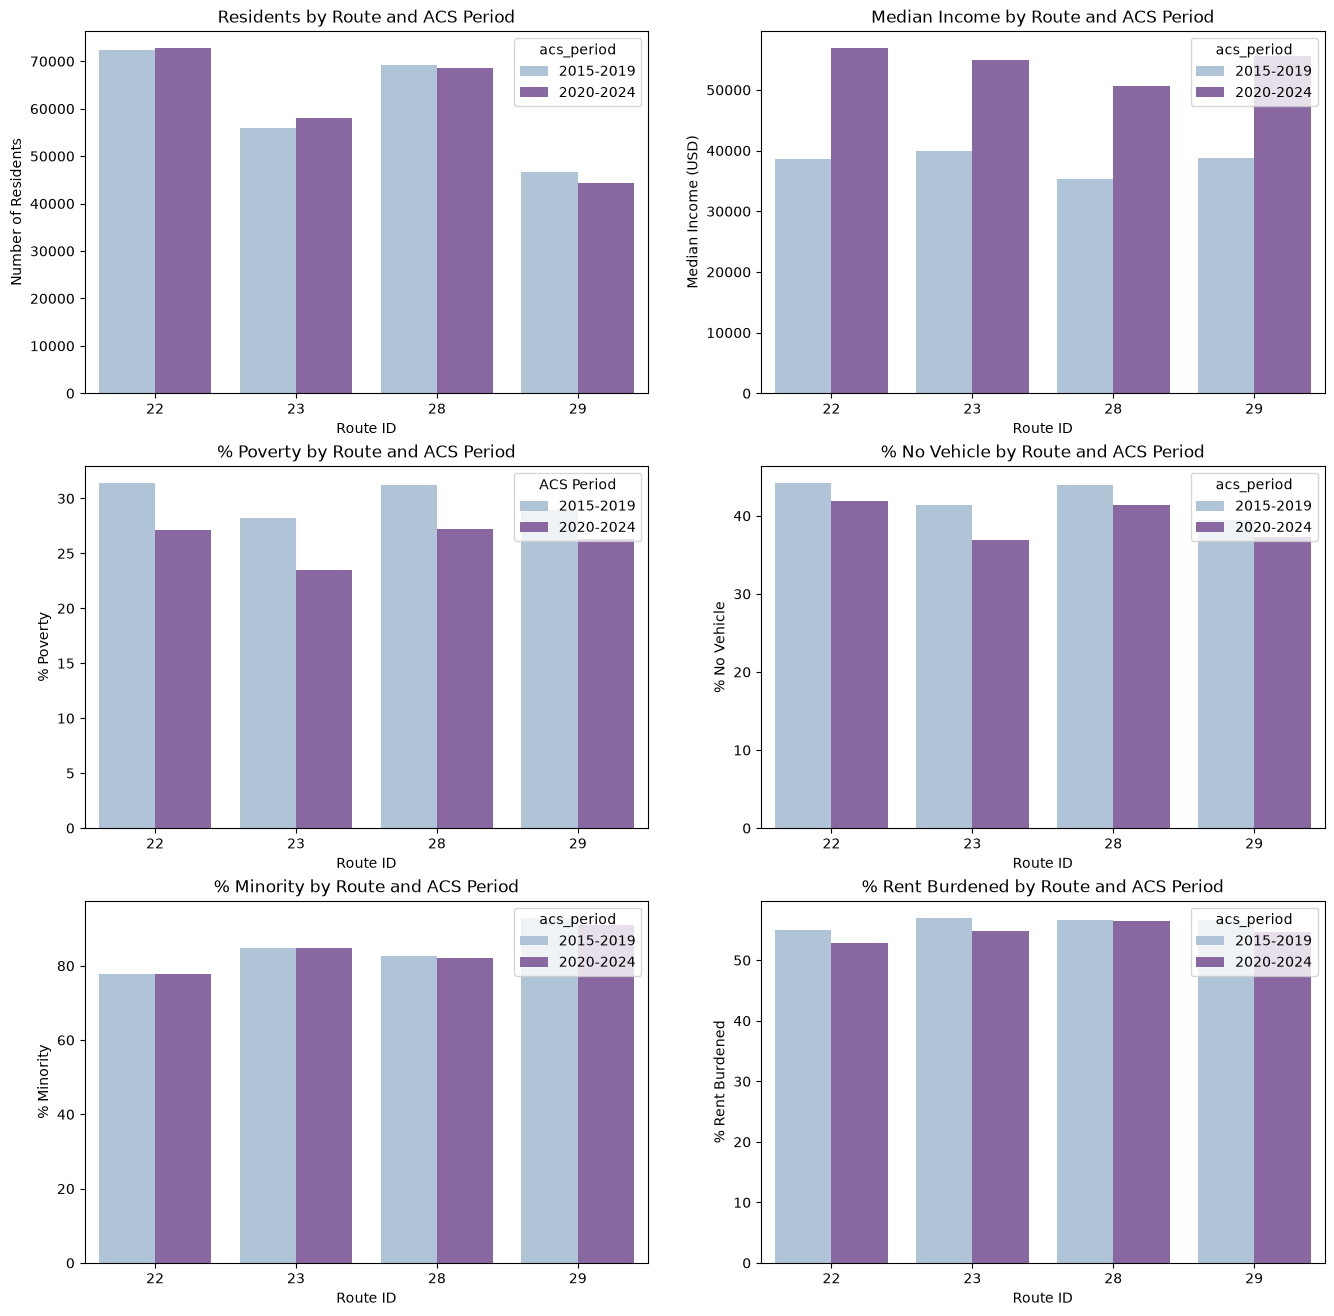

In [161]:
import matplotlib.pyplot as plt
import seaborn as sns

# Four-route profile: residents, income, poverty, no car, minority, rent burden
route_profile = demographic[demographic["route_id"].isin(routes)][["route_id", "acs_period", "fare_free", "residents", "median_income_est", "pct_poverty", "pct_no_vehicle", "pct_minority", "pct_rent_burdened"]]
print("\033[1m" + "Route Profile across Characteristics" + "\033[0m")
display(route_profile)

# Visualization
fig, axes = plt.subplots(nrows = 3, ncols= 2, figsize = (16, 16))

# residents
sns.barplot(data=route_profile, x="route_id", y="residents", hue="acs_period", palette="BuPu", ax=axes[0,0])
axes[0,0].set_title("Residents by Route and ACS Period")
axes[0,0].set_ylabel("Number of Residents")
axes[0,0].set_xlabel("Route ID")    

# median income
sns.barplot(data=route_profile, x="route_id", y="median_income_est", hue="acs_period", palette="BuPu", ax=axes[0,1])
axes[0,1].set_title("Median Income by Route and ACS Period")
axes[0,1].set_xlabel("Route ID")
axes[0,1].set_ylabel("Median Income (USD)")

# % poverty
sns.barplot(data=route_profile, x="route_id", y="pct_poverty", hue="acs_period", palette="BuPu", ax=axes[1,0])
axes[1,0].set_title("% Poverty by Route and ACS Period")
axes[1,0].set_xlabel("Route ID")
axes[1,0].set_ylabel("% Poverty")
axes[1,0].legend(loc="upper right", title="ACS Period")

# % no income
sns.barplot(data=route_profile, x="route_id", y="pct_no_vehicle", hue="acs_period", palette="BuPu", ax=axes[1,1])
axes[1,1].set_title("% No Vehicle by Route and ACS Period")
axes[1,1].set_xlabel("Route ID")
axes[1,1].set_ylabel("% No Vehicle")

# % minority
sns.barplot(data=route_profile, x="route_id", y="pct_minority", hue="acs_period", palette="BuPu", ax=axes[2,0])
axes[2,0].set_title("% Minority by Route and ACS Period")
axes[2,0].set_xlabel("Route ID")
axes[2,0].set_ylabel("% Minority")

# % rent burdened
sns.barplot(data=route_profile, x="route_id", y="pct_rent_burdened", hue="acs_period", palette="BuPu", ax=axes[2,1])
axes[2,1].set_title("% Rent Burdened by Route and ACS Period")
axes[2,1].set_xlabel("Route ID")
axes[2,1].set_ylabel("% Rent Burdened") 

# Chart B

In [194]:
# Grouped bars	Low-income, minority, no car, commuting to work: 23, 28 & 29, 22, All Bus (2025)
routes2 = ["22", "23", "28", "29", "28 & 29"]
survey = pd.read_csv("/Users/eshagupta/Downloads/CMU/Fall'26/Python/Final Project/boston-mbta-ridership/data/processed/surveys_clean.csv", dtype={'route_id': str})
survey.columns
survey_filtered = survey[(survey["survey_year"] == "2025") & 
       (survey["route_group"].isin(routes2)) &
       (
           ((survey["measure"] == "low_income") & (survey["category"] == "yes")) |
       ((survey["measure"] == "minority") & (survey["category"] == "yes")) |
       ((survey["measure"] == "vehicles") & (survey["category"] == "0")) |
       ((survey["measure"] == "trip_purpose") & (survey["category"] == "work"))
       )].copy()
survey_filtered

# making indicator names more readable
survey_filtered["indicator"] = survey_filtered["measure"]

survey_filtered.loc[survey_filtered["measure"] == "low_income", "indicator"] = "Low income"
survey_filtered.loc[survey_filtered["measure"] == "minority", "indicator"] = "Minority"
survey_filtered.loc[survey_filtered["measure"] == "vehicles", "indicator"] = "No car"
survey_filtered.loc[survey_filtered["measure"] == "trip_purpose", "indicator"] = "Commuting to work"

# pivot table
survey_pivot = survey_filtered.pivot(
    index="route_group",
    columns="indicator",
    values="pct"
)

survey_pivot


indicator,Commuting to work,Low income,Minority,No car
route_group,,,,
22,43.4,79.7,88.3,56.1
23,39.0,83.9,86.9,57.6
28 & 29,41.3,74.6,88.4,57.8


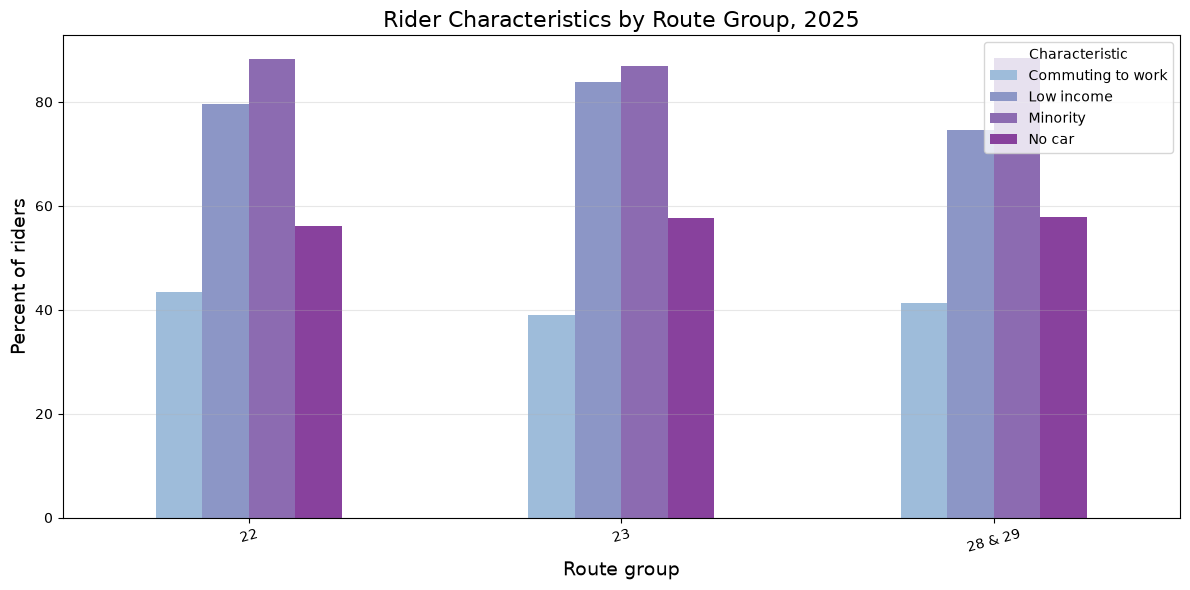

In [195]:
# Visualization
BuPu_colours = ["#9EBCDAFF", "#8C96C6FF", "#8C6BB1FF", "#88419DFF"]
    
ax = survey_pivot.plot(
    kind="bar",
    figsize=(12, 6),
    color=BuPu_colours,
)

ax.set_title("Rider Characteristics by Route Group, 2025", fontsize=16)
ax.set_xlabel("Route group", fontsize=14)
ax.set_ylabel("Percent of riders", fontsize=14)
ax.tick_params(axis="x", rotation=15)
ax.legend(title="Characteristic")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# Chart C

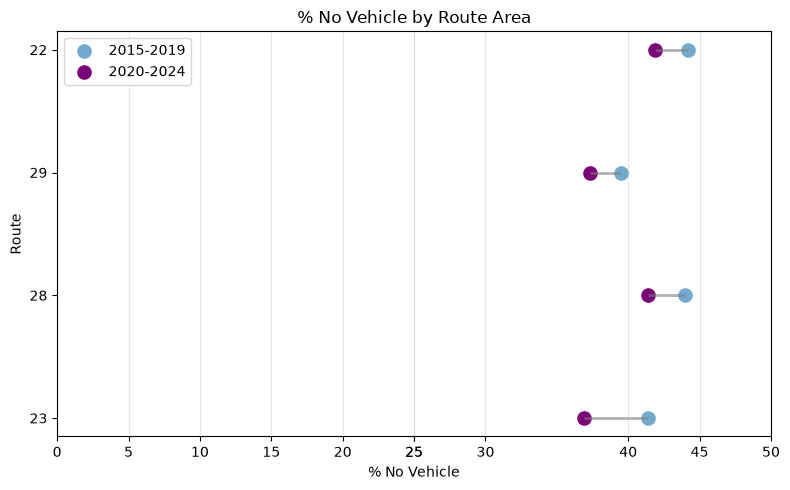

In [251]:
# Dumbbell chart: each route's neighborhood, 2015-2019 vs. 2020-2024

measure = "pct_no_vehicle"
measure_label = "% No Vehicle"

dumbbell = route_profile[
    ["route_id", "acs_period", measure]
].copy()

dumbbell_wide = dumbbell.pivot(
    index="route_id",
    columns="acs_period",
    values=measure
)

dumbbell_wide = dumbbell_wide.loc[routes]

# Visualization
fig, ax = plt.subplots(figsize=(8, 5))

y_positions = np.arange(len(dumbbell_wide))

ax.hlines(
    y=y_positions,
    xmin=dumbbell_wide["2015-2019"],
    xmax=dumbbell_wide["2020-2024"],
    color="gray",
    alpha=0.6,
    linewidth=2
)

ax.scatter(
    dumbbell_wide["2015-2019"],
    y_positions,
    color="#74a9cf",
    s=90,
    label="2015-2019"
)

ax.scatter(
    dumbbell_wide["2020-2024"],
    y_positions,
    color="#7a0177",
    s=90,
    label="2020-2024"
)

ax.set_yticks(y_positions)
ax.set_yticklabels(dumbbell_wide.index)
ax.set_xticks([0, 5, 10, 15, 20, 25, 30, 25, 40, 45, 50])

ax.set_title(f"{measure_label} by Route Area")
ax.set_xlabel(measure_label)
ax.set_ylabel("Route")


ax.legend()
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()


# Chart D

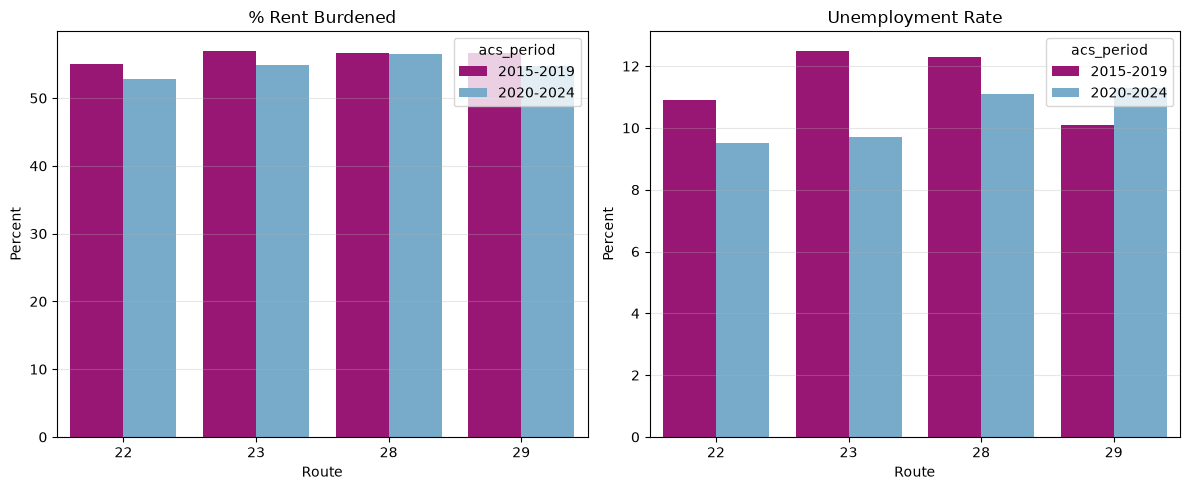

In [163]:
# Rent burden + unemployment	Side-by-side pair	pct_rent_burdened, unemployment_rate

route_profile_by_period = demographic[demographic["route_id"].isin(routes)][["route_id", "acs_period", "pct_rent_burdened", "unemployment_rate"]].copy()

colours = ["#ae017e", "#6baed6"]
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=False)

sns.barplot(
    data=route_profile_by_period,
    x="route_id",
    y="pct_rent_burdened",
    hue="acs_period",
    palette=colours[:2],
    ax=axes[0]
)

axes[0].set_title("% Rent Burdened")
axes[0].set_xlabel("Route")
axes[0].set_ylabel("Percent")
axes[0].grid(axis="y", alpha=0.3)

sns.barplot(
    data=route_profile_by_period,
    x="route_id",
    y="unemployment_rate",
    hue="acs_period",
    palette=colours[:2],
    ax=axes[1]
)

axes[1].set_title("Unemployment Rate")
axes[1].set_xlabel("Route")
axes[1].set_ylabel("Percent")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# Chart E

In [213]:


processed = r"/Users/eshagupta/Downloads/CMU/Fall'26/Python/Final Project/boston-mbta-ridership/data/processed/"     
figures   = r"/Users/eshagupta/Downloads/CMU/Fall'26/Python/Final Project/boston-mbta-ridership/figures/"           

colors = {'23': '#F6A96B', '28': '#E87A90', '29': '#B39CD0', '22': '#7FB3D5'}
routes = ['23', '28', '29', '22']
free   = ['23', '28', '29']


ridership   = pd.read_csv(processed + "ridership_route_year.csv", dtype={'route_id': str})
demographic = pd.read_csv(processed + "route_area_demographics.csv", dtype={'route_id': str})

# Weekday riders, one column per route (Silver Line excluded, same as ridership_analysis)
weekday = ridership[ridership['day_type'] == 'weekday']
riders  = weekday.pivot(index='year', columns='route_id', values='avg_daily_boardings')
# riders  = riders.drop(columns=silver_line, errors='ignore')

# % change in weekday riders, Fall 2019 -> Fall 2025
# Routes with fewer than 500 riders in 2019 are dropped (tiny routes give extreme % changes)
rider_change = (riders.loc[2025] / riders.loc[2019] - 1) * 100
rider_change = rider_change[riders.loc[2019] >= 500].dropna()

# ACS 2015-2019 goes with 2019, ACS 2020-2024 goes with 2025
acs_2019 = demographic[demographic['acs_period'] == '2015-2019'].set_index('route_id').add_suffix('_2019')
acs_2025 = demographic[demographic['acs_period'] == '2020-2024'].set_index('route_id').add_suffix('_2025')

# One table: a row per route with ridership change + both ACS periods
df = pd.DataFrame({'rider_change': rider_change}).join(acs_2019).join(acs_2025)
df['riders_2019'] = riders.loc[2019]
df['riders_2025'] = riders.loc[2025]

df.loc[routes, ['rider_change', 'riders_2019', 'riders_2025', 'residents_2019', 'residents_2025',
                'median_income_est_2019', 'median_income_est_2025']].round(1)

,rider_change,riders_2019,riders_2025,residents_2019,residents_2025,median_income_est_2019,median_income_est_2025
route_id,,,,,,,
23,1.0,11637.0,11748.6,55899.0,58015.0,39936.0,54927.0
28,-7.4,11757.8,10893.2,69296.0,68680.0,35322.0,50708.0
29,-40.9,2121.0,1254.0,46596.0,44247.0,38715.0,55527.0
22,-9.0,8411.7,7653.2,72297.0,72759.0,38561.0,56874.0


# Changes in ridership across demographics

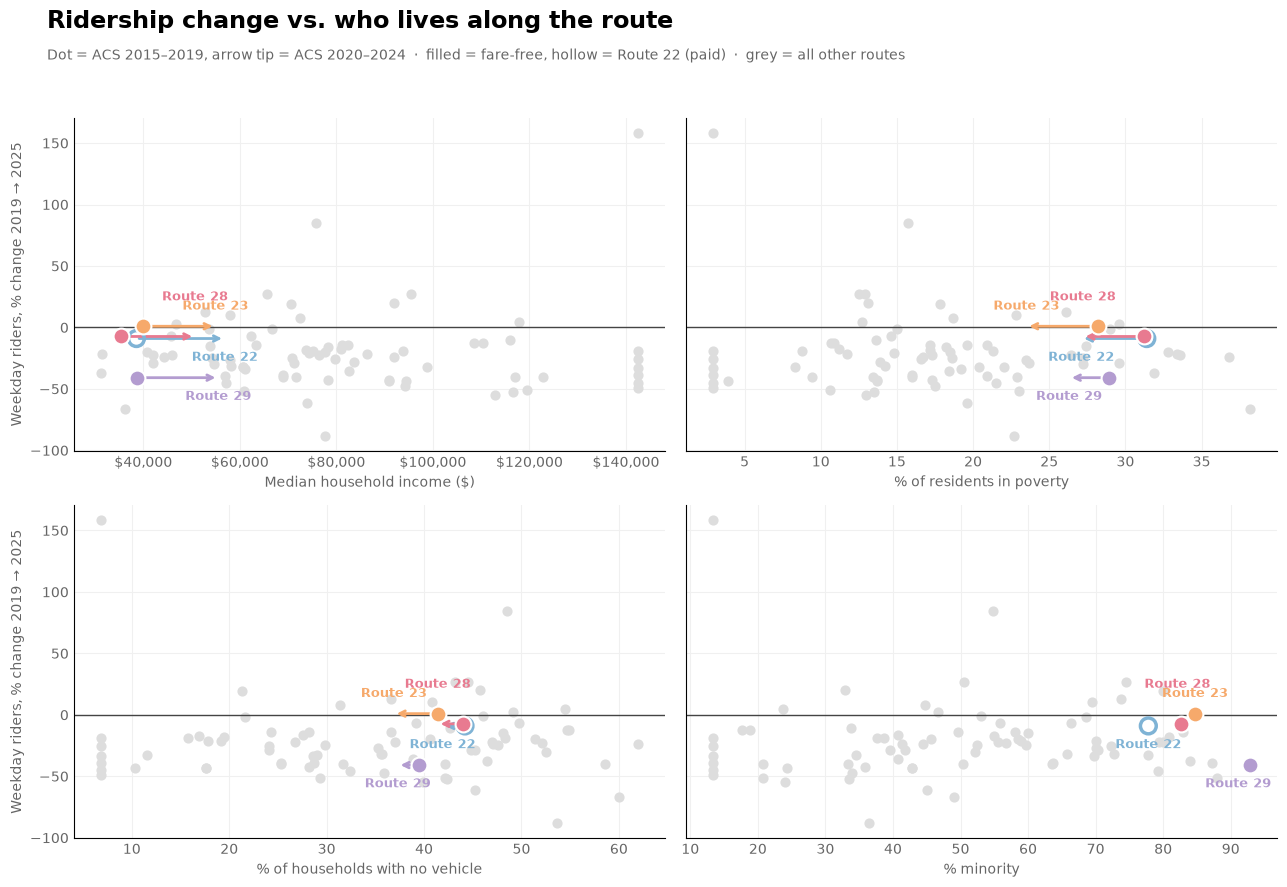

In [216]:
demos = [('median_income_est', 'Median household income ($)'),
         ('pct_poverty',       '% of residents in poverty'),
         ('pct_no_vehicle',    '% of households with no vehicle'),
         ('pct_minority',      '% minority')]

# Where each route label sits, so they do not overlap
label_offset = {'23': 12, '28': 26, '29': -16, '22': -16}

others = df[df.index.isin(routes) == False]      # every other bus route (grey background)

fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharey=True)

for ax, (col, label) in zip(axes.flatten(), demos):

    ax.scatter(others[col + '_2019'], others['rider_change'], s=40, color='#DDDDDD', zorder=1)
    ax.axhline(0, color='#444444', linewidth=1)

    for r in routes:
        x_2019 = df.loc[r, col + '_2019']
        x_2025 = df.loc[r, col + '_2025']
        y      = df.loc[r, 'rider_change']

        # arrow: where the neighborhood was (2015-2019) -> where it is now (2020-2024)
        ax.annotate('', xy=(x_2025, y), xytext=(x_2019, y),
                    arrowprops=dict(arrowstyle='->', color=colors[r], linewidth=2), zorder=2)

        # Route 22 (paid) is hollow, fare-free routes are filled
        if r == '22':
            ax.scatter(x_2019, y, s=130, facecolor='none', edgecolor=colors[r], linewidth=2.5, zorder=3)
        else:
            ax.scatter(x_2019, y, s=130, color=colors[r], edgecolor='white', linewidth=1.5, zorder=3)

        ax.annotate('Route ' + r, (x_2025, y), xytext=(0, label_offset[r]), textcoords='offset points',
                    ha='center', fontsize=9.5, fontweight='bold', color=colors[r])

    ax.set_xlabel(label, color='#666666')
    ax.grid(color='#F0F0F0')
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(length=0, colors='#666666')

axes[0, 0].set_ylabel('Weekday riders, % change 2019 → 2025', color='#666666')
axes[1, 0].set_ylabel('Weekday riders, % change 2019 → 2025', color='#666666')
axes[0, 0].xaxis.set_major_formatter(mticker.StrMethodFormatter('${x:,.0f}'))

fig.suptitle('Ridership change vs. who lives along the route', fontsize=17, fontweight='bold', x=0.04, ha='left')
fig.text(0.04, 0.925, 'Dot = ACS 2015–2019, arrow tip = ACS 2020–2024  ·  filled = fare-free, hollow = Route 22 (paid)  ·  grey = all other routes',
         fontsize=10, color='#666666')

plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.savefig(figures + '/DemographicsvsRidership.png', dpi=300, bbox_inches='tight')
plt.show()

# Resident vs Ridership

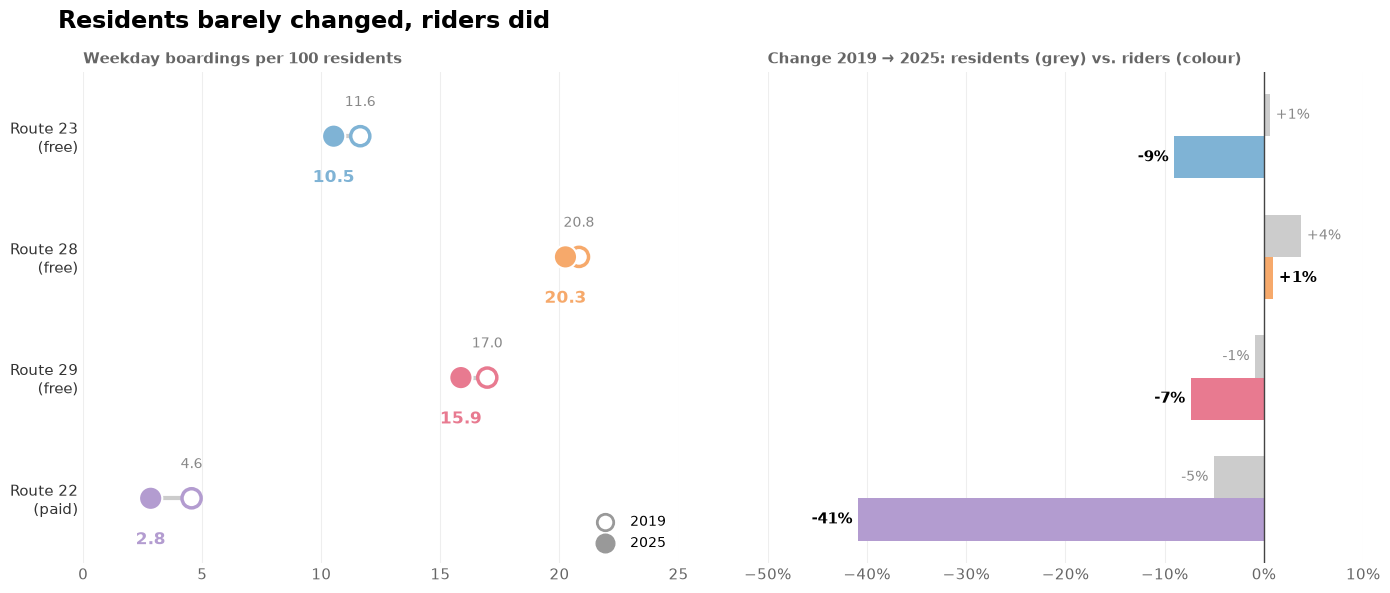

In [217]:
# Boardings per 100 residents (2019 uses ACS 2015-2019, 2025 uses ACS 2020-2024)
per100_2019 = df.loc[routes, 'riders_2019'] / df.loc[routes, 'residents_2019'] * 100
per100_2025 = df.loc[routes, 'riders_2025'] / df.loc[routes, 'residents_2025'] * 100

# % change in residents and in riders
resident_change = (df.loc[routes, 'residents_2025'] / df.loc[routes, 'residents_2019'] - 1) * 100
rider_pct       = df.loc[routes, 'rider_change']

names  = ['Route 23\n(free)', 'Route 28\n(free)', 'Route 29\n(free)', 'Route 22\n(paid)']
ypos   = [3, 2, 1, 0]
bar_colors = [colors[r] for r in routes]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

# Left: boardings per 100 residents
ax1.hlines(ypos, per100_2025, per100_2019, color='#CCCCCC', linewidth=3, zorder=2)
ax1.scatter(per100_2019, ypos, s=190, facecolor='white', edgecolor=bar_colors, linewidth=2.5, zorder=3)
ax1.scatter(per100_2025, ypos, s=280, color=bar_colors, edgecolor='white', linewidth=1.5, zorder=4)

for i in range(4):
    ax1.text(per100_2019.iloc[i], ypos[i] + 0.25, f'{per100_2019.iloc[i]:.1f}', ha='center', fontsize=10, color='#888888')
    ax1.text(per100_2025.iloc[i], ypos[i] - 0.38, f'{per100_2025.iloc[i]:.1f}', ha='center', fontsize=12, fontweight='bold', color=bar_colors[i])

ax1.scatter([], [], s=140, facecolor='white', edgecolor='#999999', linewidth=2, label='2019')
ax1.scatter([], [], s=180, color='#999999', label='2025')
ax1.legend(loc='lower right', frameon=False, fontsize=10)
ax1.set_xlim(0, 25)
ax1.set_title('Weekday boardings per 100 residents', fontsize=11, fontweight='bold', color='#666666', loc='left')

# Right: % change in residents (grey) vs % change in riders (colour)
h = 0.35
res_bars = ax2.barh([y + h/2 for y in ypos], resident_change, height=h, color='#CCCCCC', label='Residents')
ax2.bar_label(res_bars, labels=[f'{v:+.0f}%' for v in resident_change], padding=4, fontsize=10, color='#888888')
bars = ax2.barh([y - h/2 for y in ypos], rider_pct, height=h, color=bar_colors, label='Riders')
ax2.bar_label(bars, labels=[f'{v:+.0f}%' for v in rider_pct], padding=4, fontsize=11, fontweight='bold')
ax2.axvline(0, color='#444444', linewidth=1)
ax2.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax2.set_xlim(-50, 10)
ax2.set_title('Change 2019 → 2025: residents (grey) vs. riders (colour)', fontsize=11, fontweight='bold', color='#666666', loc='left')

ax1.set_yticks(ypos)
ax1.set_yticklabels(names, fontsize=12)

for ax in (ax1, ax2):
    ax.grid(axis='x', color='#EEEEEE')
    ax.set_axisbelow(True)
    ax.spines[['top', 'right', 'left', 'bottom']].set_visible(False)
    ax.tick_params(length=0, labelsize=11, colors='#666666')
ax1.tick_params(axis='y', colors='#333333')

fig.suptitle('Residents barely changed, riders did', fontsize=17, fontweight='bold', x=0.045, ha='left')
plt.tight_layout(w_pad=4)
plt.savefig(figures + '/ResidentsvsRidership.png', dpi=300, bbox_inches='tight')
plt.show()

# Neighbourhood change vs. Ridership change

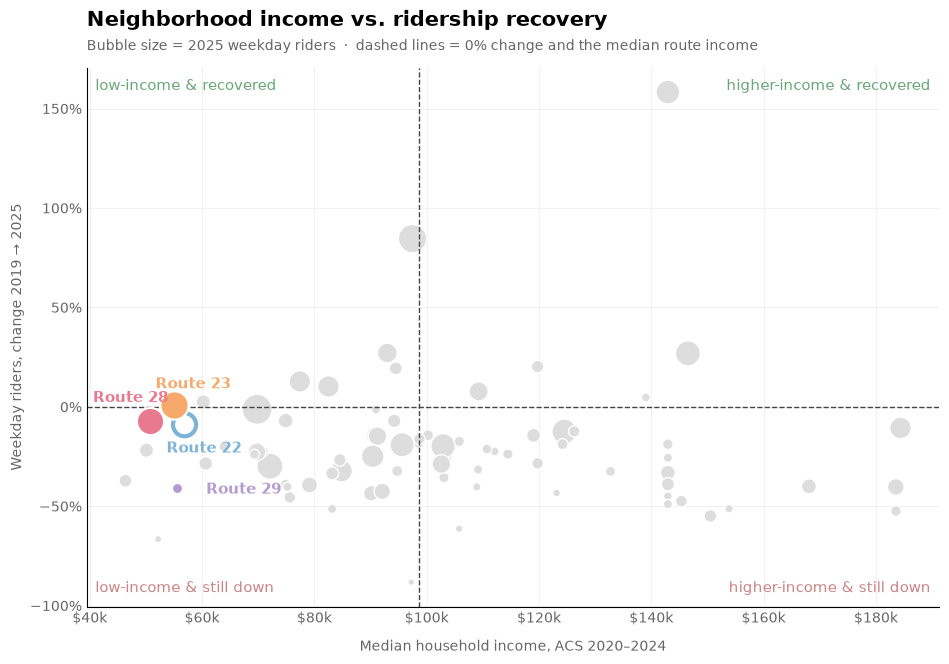

In [ ]:
income_cut = df['median_income_est_2025'].median()      # "low" vs "high" = below/above the median route

others = df[df.index.isin(routes) == False]

fig, ax = plt.subplots(figsize=(11, 7))

# Grey bubbles = other routes, bubble size = 2025 weekday riders
ax.scatter(others['median_income_est_2025'] / 1000, others['rider_change'],
           s=others['riders_2025'] / 30 + 20, color='#DDDDDD', edgecolor='white', linewidth=1, zorder=1)

ax.axhline(0, color='#444444', linewidth=1, linestyle='--')
ax.axvline(income_cut / 1000, color='#444444', linewidth=1, linestyle='--')

label_pos = {'23': (14, 12), '28': (-14, 14), '29': (48, -4), '22': (14, -20)}

for r in routes:
    x = df.loc[r, 'median_income_est_2025'] / 1000
    y = df.loc[r, 'rider_change']
    size = df.loc[r, 'riders_2025'] / 30 + 20

    if r == '22':
        ax.scatter(x, y, s=size, facecolor='none', edgecolor=colors[r], linewidth=3, zorder=3)
    else:
        ax.scatter(x, y, s=size, color=colors[r], edgecolor='white', linewidth=1.5, zorder=3)

    ax.annotate('Route ' + r, (x, y), xytext=label_pos[r], textcoords='offset points',
                ha='center', fontsize=10.5, fontweight='bold', color=colors[r])

# Quadrant labels (in axes coordinates, so they stay in the corners)
ax.text(0.01, 0.98, 'low-income & recovered', transform=ax.transAxes, ha='left', va='top', fontsize=11, color='#6AA67A')
ax.text(0.99, 0.98, 'higher-income & recovered', transform=ax.transAxes, ha='right', va='top', fontsize=11, color='#6AA67A')
ax.text(0.01, 0.02, 'low-income & still down', transform=ax.transAxes, ha='left', va='bottom', fontsize=11, color='#C98585')
ax.text(0.99, 0.02, 'higher-income & still down', transform=ax.transAxes, ha='right', va='bottom', fontsize=11, color='#C98585')

ax.xaxis.set_major_formatter(mticker.StrMethodFormatter('${x:,.0f}k'))
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_xlabel('Median household income, ACS 2020–2024', color='#666666', labelpad=10)
ax.set_ylabel('Weekday riders, change 2019 → 2025', color='#666666')
ax.grid(color='#F0F0F0')
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
ax.tick_params(length=0, colors='#666666')

ax.set_title('Neighborhood income vs. ridership recovery', fontsize=15, fontweight='bold', loc='left', pad=30)
fig.text(0.125, 0.905, 'Bubble size = 2025 weekday riders  ·  dashed lines = 0% change and the median route income',
         fontsize=10, color='#666666')

plt.savefig(figures + '/IncomevsRidershipChange.png', dpi=300, bbox_inches='tight')

plt.show()

FileNotFoundError: [Errno 2] No such file or directory: "/Users/eshagupta/Downloads/CMU/Fall'26/Python/Final Project/boston-mbta-ridership/notebooks/exploratory/path/to/figures/IncomevsRidershipChange.png"

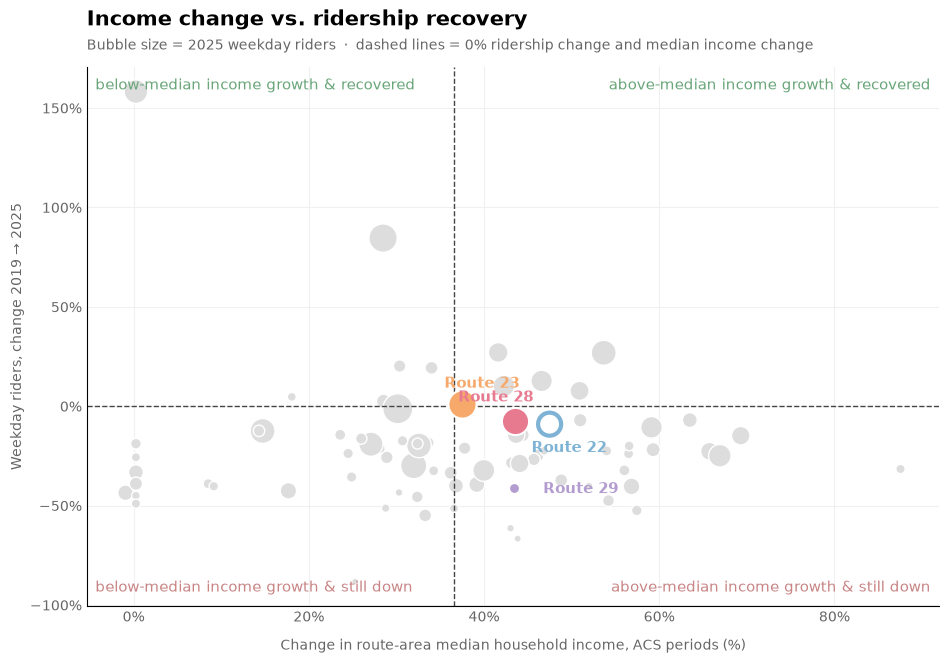

In [260]:
# change in ridership vs. change in median income, 2019 vs. 2025

# Percent change in route-area median income
df["income_change"] = (
    (df["median_income_est_2025"] / df["median_income_est_2019"]) - 1
) * 100

income_cut = df["income_change"].median()
others = df[~df.index.isin(routes)]

fig, ax = plt.subplots(figsize=(11, 7))

# Grey bubbles = other routes; bubble size = 2025 weekday riders
ax.scatter(
    others["income_change"],
    others["rider_change"],
    s=others["riders_2025"] / 30 + 20,
    color="#DDDDDD",
    edgecolor="white",
    linewidth=1,
    zorder=1,
)

ax.axhline(0, color="#444444", linewidth=1, linestyle="--")
ax.axvline(income_cut, color="#444444", linewidth=1, linestyle="--")

label_pos = {
    "23": (14, 12),
    "28": (-14, 14),
    "29": (48, -4),
    "22": (14, -20),
}

for r in routes:
    x = df.loc[r, "income_change"]
    y = df.loc[r, "rider_change"]
    size = df.loc[r, "riders_2025"] / 30 + 20

    if r == "22":
        ax.scatter(
            x, y, s=size, facecolor="none",
            edgecolor=colors[r], linewidth=3, zorder=3
        )
    else:
        ax.scatter(
            x, y, s=size, color=colors[r],
            edgecolor="white", linewidth=1.5, zorder=3
        )

    ax.annotate(
        "Route " + r,
        (x, y),
        xytext=label_pos[r],
        textcoords="offset points",
        ha="center",
        fontsize=10.5,
        fontweight="bold",
        color=colors[r],
    )

# Quadrants now describe income growth relative to the route median
ax.text(0.01, 0.98, "below-median income growth & recovered",
        transform=ax.transAxes, ha="left", va="top", fontsize=11, color="#6AA67A")
ax.text(0.99, 0.98, "above-median income growth & recovered",
        transform=ax.transAxes, ha="right", va="top", fontsize=11, color="#6AA67A")
ax.text(0.01, 0.02, "below-median income growth & still down",
        transform=ax.transAxes, ha="left", va="bottom", fontsize=11, color="#C98585")
ax.text(0.99, 0.02, "above-median income growth & still down",
        transform=ax.transAxes, ha="right", va="bottom", fontsize=11, color="#C98585")

ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_xlabel("Change in route-area median household income, ACS periods (%)",
              color="#666666", labelpad=10)
ax.set_ylabel("Weekday riders, change 2019 → 2025", color="#666666")
ax.grid(color="#F0F0F0")
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(length=0, colors="#666666")

ax.set_title("Income change vs. ridership recovery",
             fontsize=15, fontweight="bold", loc="left", pad=30)
fig.text(
    0.125, 0.905,
    "Bubble size = 2025 weekday riders  ·  dashed lines = 0% ridership change and median income change",
    fontsize=10, color="#666666",
)

plt.savefig(figures + "/IncomevsRidershipChange.png", dpi=300, bbox_inches="tight")
plt.show()

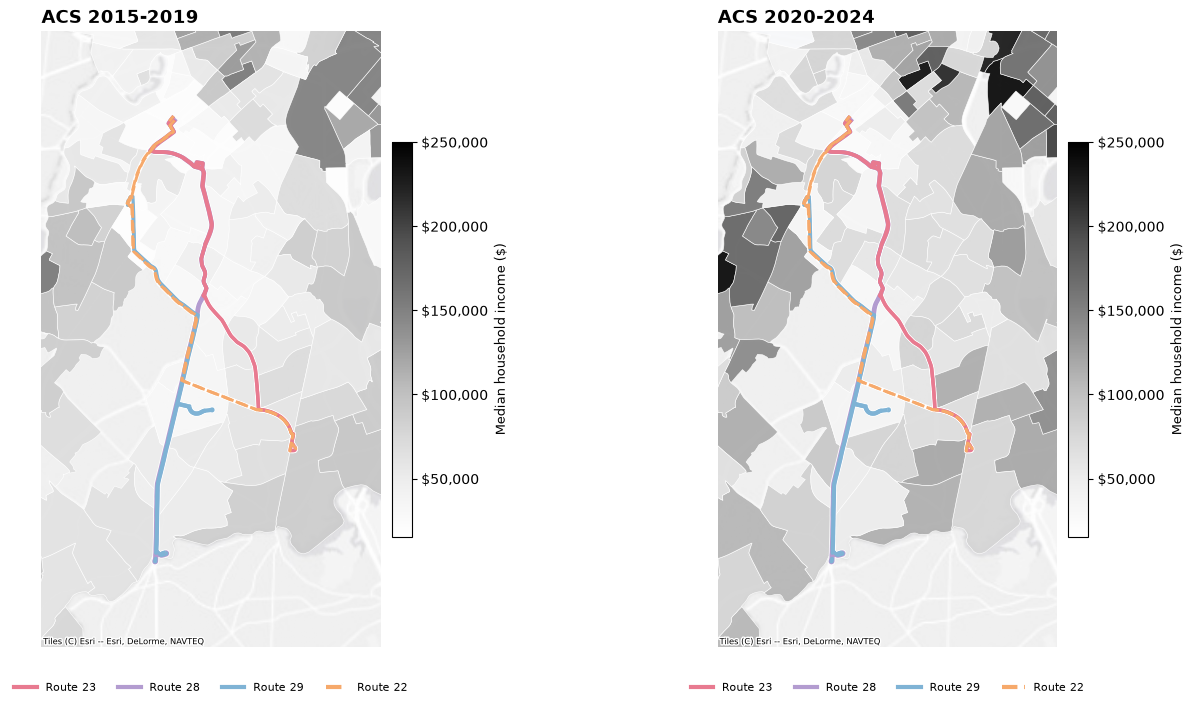

In [256]:
# Visualization
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 8))

# Shared grayscale income scale for both panels
income_cmap = "Greys"

vmin = min(
    boston19["median_hh_income"].min(),
    boston24["median_hh_income"].min()
)

vmax = max(
    boston19["median_hh_income"].max(),
    boston24["median_hh_income"].max()
)

minx, miny, maxx, maxy = route_lines.total_bounds
pad = 1500

widths = {
    "28": 2.8,
    "23": 2.5,
    "29": 2.3,
    "22": 2.1
}

route_legend = [
    Line2D([0], [0], color=map_colors["23"], linewidth=3, label="Route 23"),
    Line2D([0], [0], color=map_colors["28"], linewidth=3, label="Route 28"),
    Line2D([0], [0], color=map_colors["29"], linewidth=3, label="Route 29"),
    Line2D(
        [0], [0],
        color=map_colors["22"],
        linewidth=3,
        linestyle="--",
        label="Route 22"
    )
]

# ACS 2015-2019 map
boston19.plot(
    column="median_hh_income",
    cmap=income_cmap,
    vmin=vmin,
    vmax=vmax,
    ax=axes[0],
    edgecolor="#FFFFFF",
    linewidth=0.45,
    alpha=0.9,
    missing_kwds={"color": "#F7F8FA"}
)

ctx.add_basemap(
    axes[0],
    source=ctx.providers.Esri.WorldGrayCanvas,
    crs=boston19.crs,
    alpha=0.65,
    attribution_size=6,
    zorder=0
)

for route in ["28", "23", "29", "22"]:
    line = route_lines[route_lines["route_id"] == route]

    line.plot(
        ax=axes[0],
        color="white",
        linewidth=widths[route] + 1.2,
        zorder=3
    )

    line.plot(
        ax=axes[0],
        color=map_colors[route],
        linewidth=widths[route],
        linestyle="--" if route == "22" else "-",
        zorder=4
    )

axes[0].set_xlim(minx - pad, maxx + pad)
axes[0].set_ylim(miny - pad, maxy + pad)
axes[0].set_title("ACS 2015-2019", fontsize=13, fontweight="bold", loc="left")
axes[0].set_axis_off()

income_scale_19 = plt.cm.ScalarMappable(
    norm=plt.Normalize(vmin=vmin, vmax=vmax),
    cmap=income_cmap
)

cbar_19 = fig.colorbar(
    income_scale_19,
    ax=axes[0],
    orientation="vertical",
    fraction=0.035,
    pad=0.02
)

cbar_19.set_label("Median household income ($)", fontsize=9)
cbar_19.ax.yaxis.set_major_formatter(
    mticker.StrMethodFormatter("${x:,.0f}")
)

axes[0].legend(
    handles=route_legend,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.04),
    ncol=4,
    frameon=False,
    fontsize=8
)

# ACS 2020-2024 map
boston24.plot(
    column="median_hh_income",
    cmap=income_cmap,
    vmin=vmin,
    vmax=vmax,
    ax=axes[1],
    edgecolor="#FFFFFF",
    linewidth=0.45,
    alpha=0.9,
    missing_kwds={"color": "#F7F8FA"}
)

ctx.add_basemap(
    axes[1],
    source=ctx.providers.Esri.WorldGrayCanvas,
    crs=boston24.crs,
    alpha=0.65,
    attribution_size=6,
    zorder=0
)

for route in ["28", "23", "29", "22"]:
    line = route_lines[route_lines["route_id"] == route]

    line.plot(
        ax=axes[1],
        color="white",
        linewidth=widths[route] + 1.2,
        zorder=3
    )

    line.plot(
        ax=axes[1],
        color=map_colors[route],
        linewidth=widths[route],
        linestyle="--" if route == "22" else "-",
        zorder=4
    )

axes[1].set_xlim(minx - pad, maxx + pad)
axes[1].set_ylim(miny - pad, maxy + pad)
axes[1].set_title("ACS 2020-2024", fontsize=13, fontweight="bold", loc="left")
axes[1].set_axis_off()

income_scale_24 = plt.cm.ScalarMappable(
    norm=plt.Normalize(vmin=vmin, vmax=vmax),
    cmap=income_cmap
)

cbar_24 = fig.colorbar(
    income_scale_24,
    ax=axes[1],
    orientation="vertical",
    fraction=0.035,
    pad=0.02
)

cbar_24.set_label("Median household income ($)", fontsize=9)
cbar_24.ax.yaxis.set_major_formatter(
    mticker.StrMethodFormatter("${x:,.0f}")
)

axes[1].legend(
    handles=route_legend,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.04),
    ncol=4,
    frameon=False,
    fontsize=8
)



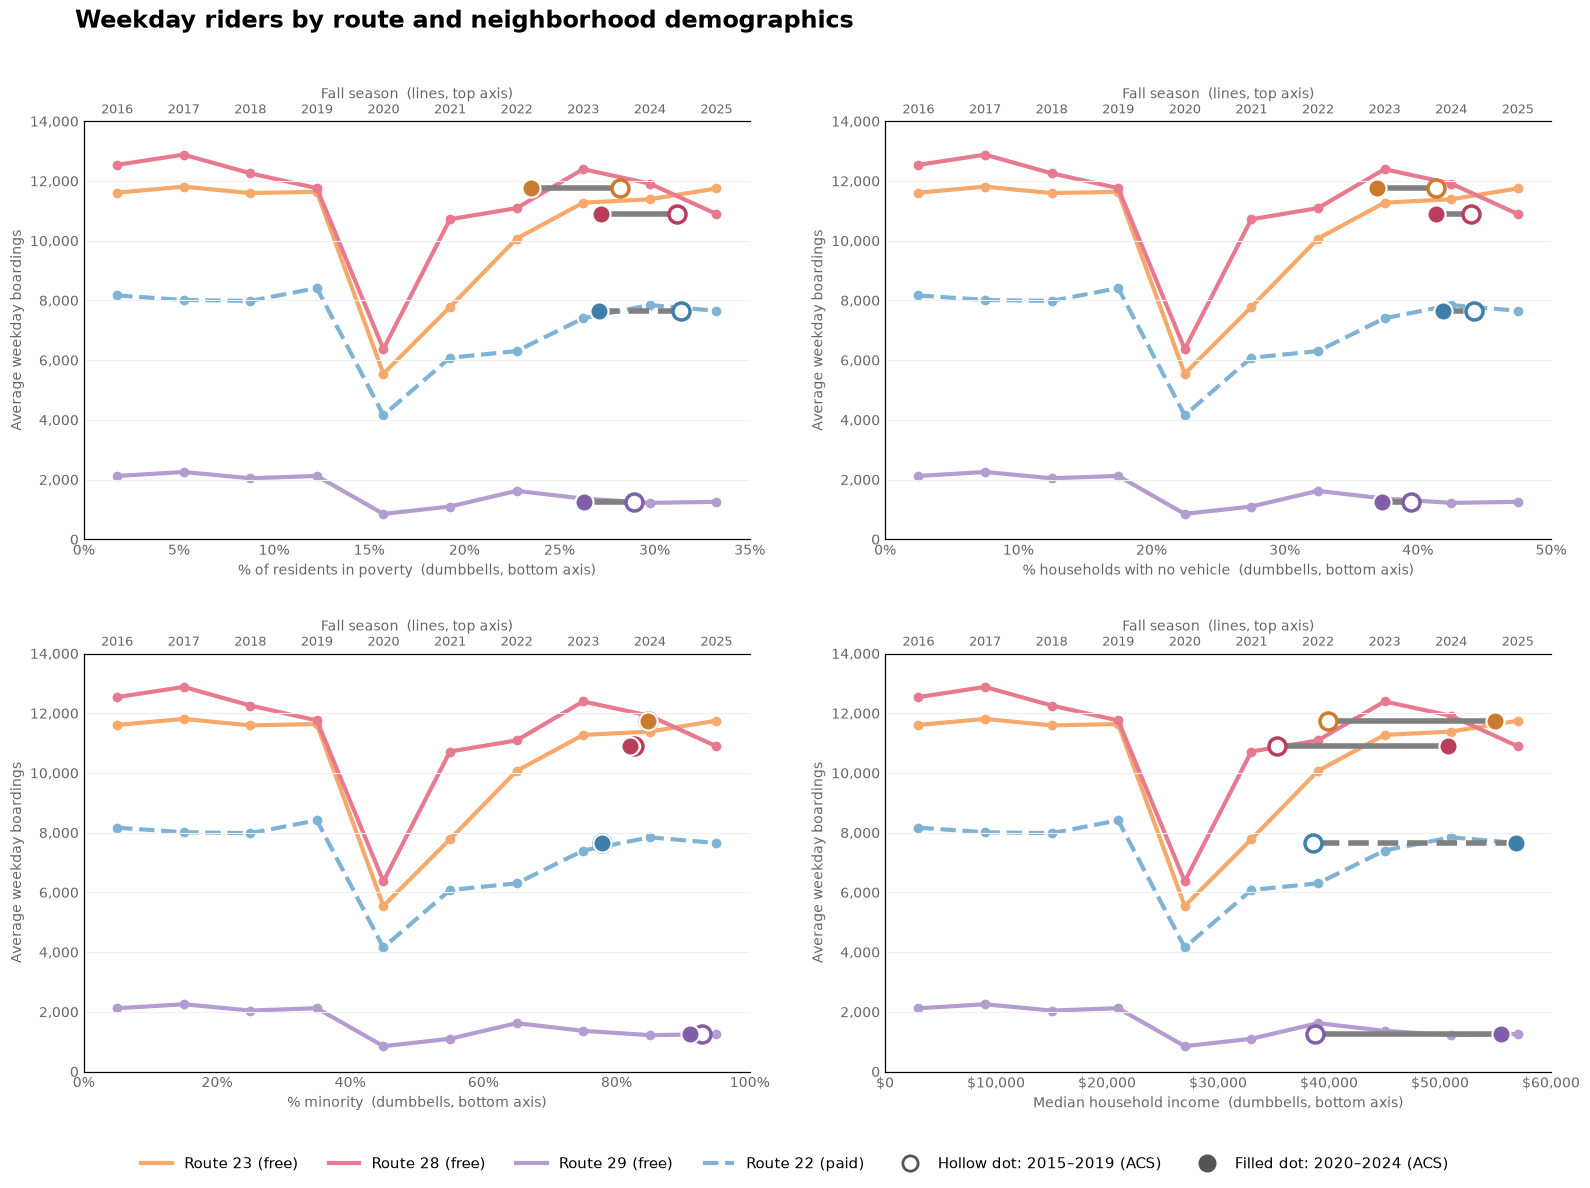

In [259]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D

dumbbell_year = 2025                 # NEW: the dumbbells sit at each route's riders in this year

colors = {'23': '#F6A96B', '28': '#E87A90', '29': '#B39CD0', '22': '#7FB3D5'}
dark   = {'23': '#C97B2E', '28': '#B83E5C', '29': '#7E5FA8', '22': '#3F7FA8'}    # NEW: darker colours for the dumbbell dots
routes = ['23', '28', '29', '22']

# NEW: one entry per panel -> (column in the csv, panel title, x-axis max, tick step)
demos = [('pct_poverty',       '% of residents in poverty',    35,    5),
         ('pct_no_vehicle',    '% households with no vehicle', 50,    10),
         ('pct_minority',      '% minority',                   100,   20),
         ('median_income_est', 'Median household income',      60000, 10000)]
# ========================================================

ridership   = pd.read_csv(processed + '/ridership_route_year.csv', dtype={'route_id': str})
demographic = pd.read_csv(processed + '/route_area_demographics.csv', dtype={'route_id': str})

# Weekday riders, one column per route
weekday = ridership[ridership['day_type'] == 'weekday']
riders  = weekday.pivot(index='year', columns='route_id', values='avg_daily_boardings')

# Demographic for both periods
acs_pre  = demographic[demographic['acs_period'] == '2015-2019'].set_index('route_id')
acs_post = demographic[demographic['acs_period'] == '2020-2024'].set_index('route_id')

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

for ax, (col, title, x_max, step) in zip(axes.flatten(), demos):

    ax_top = ax.twiny()                   # second x-axis (top) for the years

    # ---- ridership lines (top axis = years) ----
    for r in routes:
        ax_top.plot(riders.index, riders[r], color=colors[r], linewidth=3, marker='o',
                    linestyle='--' if r == '22' else '-')

    # ---- dumbbells (bottom axis = the demographic), height = riders in dumbbell_year ----
    for r in routes:
        y      = riders.loc[dumbbell_year, r]
        x_pre  = acs_pre.loc[r, col]
        x_post = acs_post.loc[r, col]

        ax.hlines(y, x_post, x_pre, color='grey', linewidth=4,
                  linestyle='--' if r == '22' else '-', zorder=3)                              # black line, 22 (paid) dashed
        ax.scatter(x_pre, y, s=150, facecolor='white', edgecolor=dark[r], linewidth=2.5, zorder=4)     # hollow = 2015-2019
        ax.scatter(x_post, y, s=170, color=dark[r], edgecolor='white', linewidth=1.5, zorder=5)        # filled = 2020-2024

    # Dumbbells are drawn on top of the lines
    ax.set_zorder(ax_top.get_zorder() + 1)
    ax.patch.set_visible(False)

    # ---- axes ----
    ax.set_xlim(0, x_max)
    ax.set_xticks(range(0, x_max + 1, step))
    ax_top.set_xlim(2015.5, 2025.5)
    ax_top.set_xticks(range(2016, 2026))
    ax.set_ylim(0, 14000)

    ax.yaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
    if col == 'median_income_est':
        ax.xaxis.set_major_formatter(mticker.StrMethodFormatter('${x:,.0f}'))
    else:
        ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))

    ax.set_xlabel(title + '  (dumbbells, bottom axis)', color='#666666')
    ax_top.set_xlabel('Fall season  (lines, top axis)', color='#666666')
    ax.set_ylabel('Average weekday boardings', color='#666666')

    ax.grid(axis='y', color='#F0F0F0')
    ax.spines[['right']].set_visible(False)
    ax_top.spines[['right']].set_visible(False)
    ax.tick_params(length=0, colors='#666666')
    ax_top.tick_params(length=0, colors='#666666', labelsize=9)

# ---- legend (one for the whole figure) ----
handles = [Line2D([0], [0], color=colors['23'], linewidth=3, label='Route 23 (free)'),
           Line2D([0], [0], color=colors['28'], linewidth=3, label='Route 28 (free)'),
           Line2D([0], [0], color=colors['29'], linewidth=3, label='Route 29 (free)'),
           Line2D([0], [0], color=colors['22'], linewidth=3, linestyle='--', label='Route 22 (paid)'),
           Line2D([0], [0], marker='o', linestyle='', markersize=11, markerfacecolor='white', markeredgecolor='#555555',
                  markeredgewidth=2, label='Hollow dot: 2015–2019 (ACS)'),
           Line2D([0], [0], marker='o', linestyle='', markersize=12, color='#555555', label='Filled dot: 2020–2024 (ACS)')]
fig.legend(handles=handles, loc='lower center', ncol=6, frameon=False, fontsize=11, bbox_to_anchor=(0.5, 0.0))

fig.suptitle('Weekday riders by route and neighborhood demographics', fontsize=17, fontweight='bold', x=0.05, ha='left')
plt.tight_layout(rect=[0, 0.05, 1, 0.96], h_pad=3, w_pad=3)
plt.show()